# Time Series Pipeline: African Economic, Banking and Systemic Crises
**Task 1: Preprocessing, EDA, Analytical Questions and Modeling**

By Yves Niyigena

**Dataset:** Africa Economic, Banking and Systemic Crisis Data (Kaggle), annual data for 13 African countries.
**Target:** `banking_crisis` (binary classification: will a country-year be in a banking crisis?)

## 0. Setup

In [ ]:
# !pip install xgboost -q   # only if you want XGBoost (optional)
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, os, warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.makedirs(PROJECT_ROOT / "models", exist_ok=True)
os.makedirs(PROJECT_ROOT / "data/processed", exist_ok=True)

ModuleNotFoundError: No module named 'seaborn'

## 1. Load the data

In [3]:
from pathlib import Path
import pandas as pd

# Resolve paths when launched from the project root or the notebooks directory.
candidates = [
    Path("data/raw/african_crises.csv"),
    Path("../data/raw/african_crises.csv"),
    Path("african_crises.csv"),
]
CSV = next((path for path in candidates if path.exists()), None)
if CSV is None:
    try:
        from google.colab import files
        files.upload()
        CSV = Path("african_crises.csv")
    except ImportError as error:
        raise FileNotFoundError("Could not find data/raw/african_crises.csv") from error

df = pd.read_csv(CSV)
df = df.sort_values(["country", "year"]).reset_index(drop=True)
df.head()

,case,cc3,country,year,systemic_crisis,exch_usd,domestic_debt_in_default,sovereign_external_debt_default,gdp_weighted_default,inflation_annual_cpi,independence,currency_crises,inflation_crises,banking_crisis
0,1,DZA,Algeria,1870,1,0.052264,0,0,0.0,3.441456,0,0,0,crisis
1,1,DZA,Algeria,1871,0,0.052798,0,0,0.0,14.149140,0,0,0,no_crisis
2,1,DZA,Algeria,1872,0,0.052274,0,0,0.0,-3.718593,0,0,0,no_crisis
3,1,DZA,Algeria,1873,0,0.051680,0,0,0.0,11.203897,0,0,0,no_crisis
4,1,DZA,Algeria,1874,0,0.051308,0,0,0.0,-3.848561,0,0,0,no_crisis


## Task 1A: Understanding the dataset

In [3]:
print("Shape:", df.shape)
print("Time range:", df.year.min(), "->", df.year.max())
print("Countries:", df.country.nunique(), sorted(df.country.unique()))
print("\nDtypes:\n", df.dtypes)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate (country, year):", df.duplicated(["country", "year"]).sum())

Shape: (1059, 14)
Time range: 1860 -> 2014
Countries: 13 ['Algeria', 'Angola', 'Central African Republic', 'Egypt', 'Ivory Coast', 'Kenya', 'Mauritius', 'Morocco', 'Nigeria', 'South Africa', 'Tunisia', 'Zambia', 'Zimbabwe']

Dtypes:
 case                                 int64
cc3                                 object
country                             object
year                                 int64
systemic_crisis                      int64
exch_usd                           float64
domestic_debt_in_default             int64
sovereign_external_debt_default      int64
gdp_weighted_default               float64
inflation_annual_cpi               float64
independence                         int64
currency_crises                      int64
inflation_crises                     int64
banking_crisis                      object
dtype: object

Missing values per column:
 case                               0
cc3                                0
country                            0
year      

### Frequency and gaps

In [4]:
df["gap"] = df.groupby("country").year.diff()
print("Gap between consecutive observations (years):")
print(df.gap.value_counts())

span = df.groupby("country").year.agg(["min", "max", "count"])
span["expected"] = span["max"] - span["min"] + 1
span["missing_years"] = span["expected"] - span["count"]
span

Gap between consecutive observations (years):
gap
1.0     1040
55.0       1
7.0        1
8.0        1
11.0       1
2.0        1
4.0        1
Name: count, dtype: int64


,min,max,count,expected,missing_years
country,,,,,
Algeria,1870,2014,85,145,60
Angola,1921,2014,77,94,17
Central African Republic,1957,2014,58,58,0
Egypt,1860,2014,155,155,0
Ivory Coast,1952,2014,63,63,0
Kenya,1948,2014,67,67,0
Mauritius,1947,2014,68,68,0
Morocco,1940,2014,75,75,0
Nigeria,1954,2014,60,61,1


### Findings
- **Frequency:** Annual.
- **Missing values:** None in any column.
- **Missing years:** Algeria (60) and Angola (17) have large gaps; Zimbabwe (3) and Nigeria (1) have small ones.
- **Handling decision:** We do **not** interpolate or reindex to a full yearly range to avoid synthetic data bias. Lags and moving averages are computed per country using true calendar years, and rows with incomplete history are dropped for modeling.

### Statistical distributions

,count,mean,std,min,25%,50%,75%,max
exch_usd,1059.0,43.140831,111.475380,0.000000,0.195350,0.86840,8.462750,7.443061e+02
inflation_annual_cpi,1059.0,20848.892444,675727.429176,-28.502137,2.086162,5.76233,11.644048,2.198970e+07
gdp_weighted_default,1059.0,0.006402,0.043572,0.000000,0.000000,0.00000,0.000000,4.000000e-01


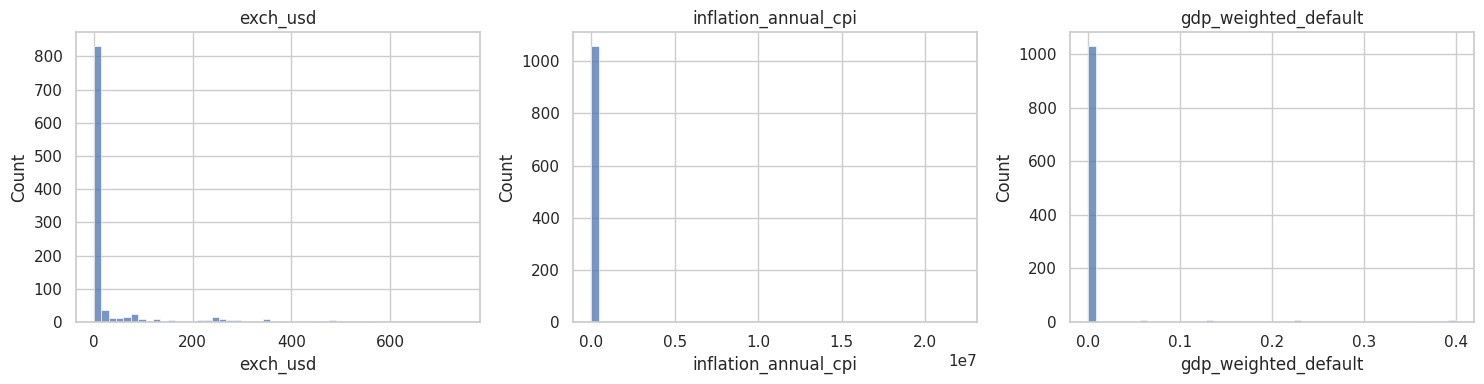

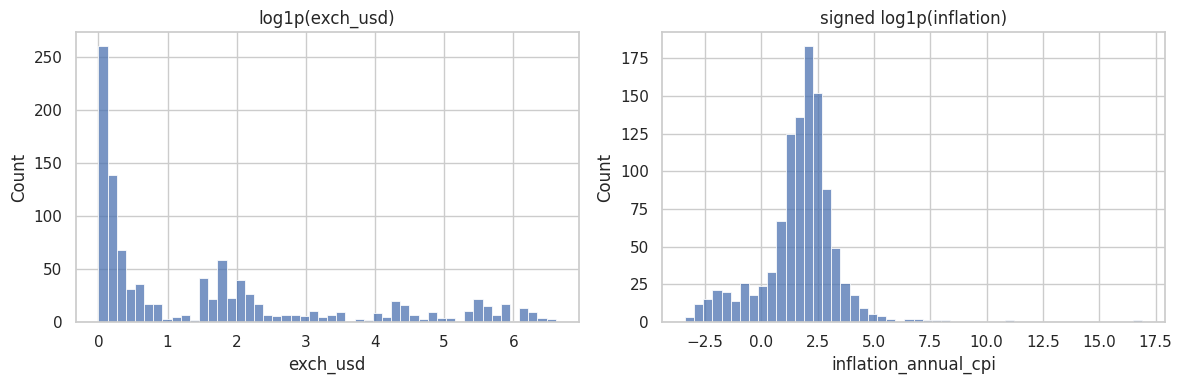

Largest inflation value:


,1053
country,Zimbabwe
year,2008
inflation_annual_cpi,21989695.22


In [5]:
num_cols = ["exch_usd", "inflation_annual_cpi", "gdp_weighted_default"]
display(df[num_cols].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], bins=50, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

# Heavy tails -> log scale view
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(df.exch_usd), bins=50, ax=axes[0]); axes[0].set_title("log1p(exch_usd)")
sns.histplot(np.sign(df.inflation_annual_cpi) * np.log1p(df.inflation_annual_cpi.abs()), bins=50, ax=axes[1])
axes[1].set_title("signed log1p(inflation)")
plt.tight_layout(); plt.show()

print("Largest inflation value:")
display(df.loc[df.inflation_annual_cpi.idxmax(), ["country", "year", "inflation_annual_cpi"]])

**Interpretation (fill in):** `exch_usd` and `inflation_annual_cpi` are extremely right-skewed. The maximum inflation (Zimbabwe, 2008, about 2.2e7 %) is real hyperinflation, not a data error, so we **transform (signed log1p) instead of deleting** it.

### Binary / categorical columns and target balance

{0: 977, 1: 82} <- systemic_crisis
{0: 1017, 1: 42} <- domestic_debt_in_default
{0: 897, 1: 162} <- sovereign_external_debt_default
{1: 822, 0: 237} <- independence
{0: 923, 1: 132, 2: 4} <- currency_crises
{0: 922, 1: 137} <- inflation_crises
{'no_crisis': 965, 'crisis': 94} <- banking_crisis

Target share:
banking_crisis
no_crisis    0.911
crisis       0.089
Name: proportion, dtype: float64


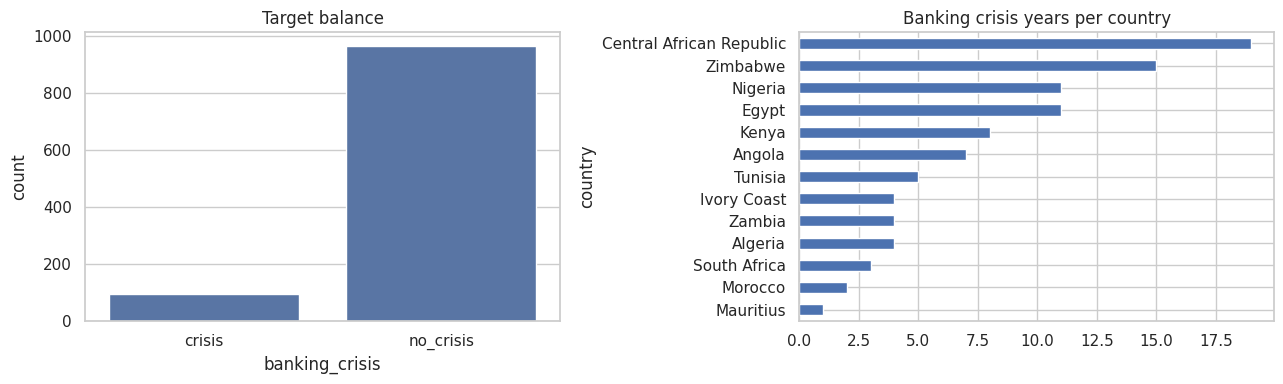

In [6]:
bin_cols = ["systemic_crisis", "domestic_debt_in_default", "sovereign_external_debt_default",
            "independence", "currency_crises", "inflation_crises", "banking_crisis"]
for c in bin_cols:
    print(df[c].value_counts().to_dict(), "<-", c)

print("\nTarget share:")
print(df.banking_crisis.value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x="banking_crisis", data=df, ax=axes[0]); axes[0].set_title("Target balance")
df.groupby("country").banking_crisis.apply(lambda s: (s == "crisis").sum()).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Banking crisis years per country")
plt.tight_layout(); plt.show()

**Notes (fill in):** the target is imbalanced (~9% crisis), so accuracy is misleading; we use precision, recall, F1 and PR-AUC. `currency_crises` has 4 rows with value 2, which we cap to 1 (documented in preprocessing).

## Preprocessing pipeline
This cell is the code that will later move to `src/preprocessing.py` and be reused in Task 4 (prediction script).

In [ ]:
import sys

project_root = PROJECT_ROOT
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import BASE_NUM, FEATURES, LAGS, ROLL, TARGET, add_time_features, clean_records

clean_df = clean_records(df.to_dict(orient="records"))
feat_df = add_time_features(clean_df)

model_df = feat_df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print("Rows before / after dropping rows without enough history:", len(feat_df), "/", len(model_df))
model_df.to_csv(project_root / "data/processed/crises_features.csv", index=False)
model_df[["country", "year", TARGET] + FEATURES].head()

Rows before / after dropping rows without enough history: 1059 / 1002


,country,year,banking_crisis,systemic_crisis,domestic_debt_in_default,sovereign_external_debt_default,gdp_weighted_default,independence,currency_crises,inflation_crises,exch_usd_log,inflation_log,inflation_change,crisis_lag1,exch_usd_lag1,exch_usd_lag2,inflation_log_lag1,inflation_log_lag2,exch_usd_ma3,inflation_log_ma3
0,Algeria,1873,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.050389,2.501755,4.053266,0.0,0.052274,0.052798,-1.551511,2.717944,0.052445,0.885805
1,Algeria,1874,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.050035,-1.578682,-4.080437,0.0,0.051680,0.052274,2.501755,-1.551511,0.052251,1.222729
2,Algeria,1875,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.050261,-3.087590,-1.508908,0.0,0.051308,0.051680,-1.578682,2.501755,0.051754,-0.209479
3,Algeria,1876,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.050567,-1.018684,2.068906,0.0,0.051546,0.051308,-3.087590,-1.578682,0.051511,-0.721506
4,Algeria,1877,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.050567,3.405058,4.423742,0.0,0.051867,0.051546,-1.018684,-3.087590,0.051574,-1.894985


**Why this design (for the report):** (1) lags/rolling windows are computed per country so one country's history never leaks into another; (2) moving averages use `shift(1)` so they only see *past* years; (3) rows without enough history are dropped rather than imputed; (4) the target is encoded 0/1.

## Task 1B: Analytical questions
Each question has a visualization and an interpretation. Write the interpretation after you read the output.

### Q1. Is there a long-term trend in inflation and exchange rates across the continent?

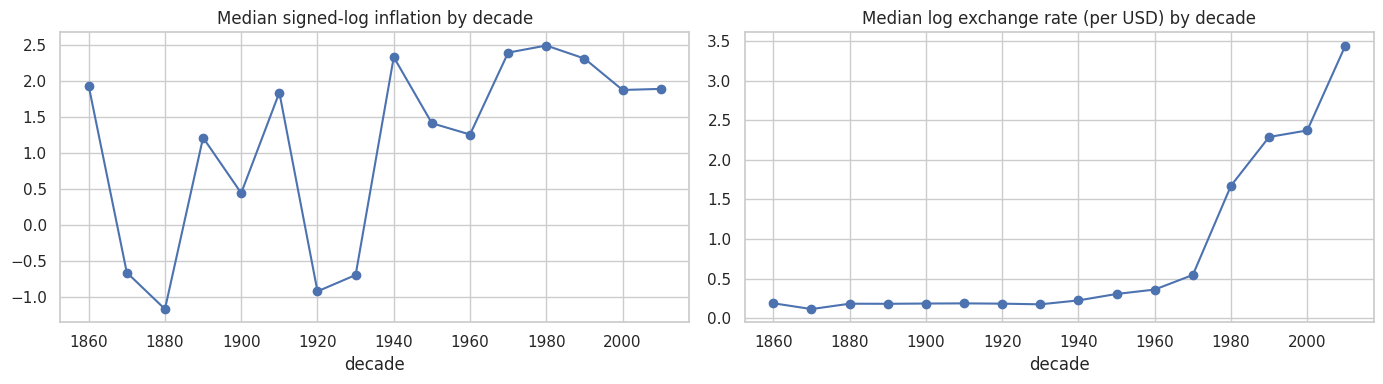

In [8]:
d = clean_df.copy()
d["decade"] = (d.year // 10) * 10
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
d.groupby("decade").inflation_log.median().plot(marker="o", ax=axes[0]); axes[0].set_title("Median signed-log inflation by decade")
d.groupby("decade").exch_usd_log.median().plot(marker="o", ax=axes[1]); axes[1].set_title("Median log exchange rate (per USD) by decade")
plt.tight_layout(); plt.show()

### Interpretation
- **Exchange rates:** The median log exchange rate rises strongly in later decades, from 0.546 in the 1970s to 3.446 in the 2010s.
- **Inflation:** Median signed-log inflation is not monotonic: it increases through the 1970s-1980s, then moderates (2.500 in the 1980s, 2.318 in the 1990s, and about 1.9 in the 2000s-2010s). Hyperinflation and sparse early observations make continent-wide decade summaries sensitive to outliers and coverage.

### Q2. How has the frequency of banking crises changed over time?

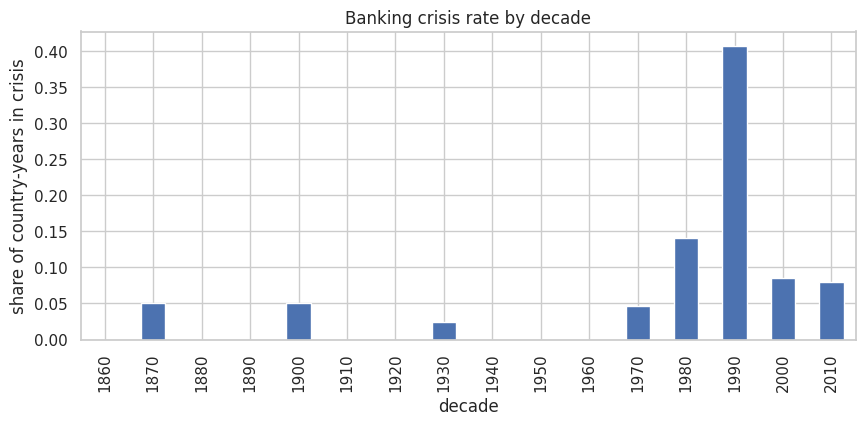

,crisis_years,obs,rate
decade,,,
1860,0,10,0.000000
1870,1,20,0.050000
1880,0,15,0.000000
1890,0,10,0.000000
1900,1,20,0.050000
1910,0,20,0.000000
1920,0,35,0.000000
1930,1,41,0.024390
1940,0,82,0.000000


In [9]:
d["is_crisis"] = d.banking_crisis
by_dec = d.groupby("decade").agg(crisis_years=("is_crisis", "sum"), obs=("is_crisis", "size"))
by_dec["rate"] = by_dec.crisis_years / by_dec.obs
fig, ax = plt.subplots(figsize=(10, 4))
by_dec.rate.plot.bar(ax=ax); ax.set_ylabel("share of country-years in crisis"); ax.set_title("Banking crisis rate by decade")
plt.show(); by_dec

### Interpretation
- **Concentration:** Banking crises heavily concentrated in the 1990s, where over 40% of country-years experienced a crisis.
- **Historical context:** Early decades (1860s–1950s) show near-zero or extremely low crisis rates, though data points are sparse and noisy.

### Q3. Are there lag effects: do past inflation and exchange-rate values relate to a banking crisis now? (lagged features)

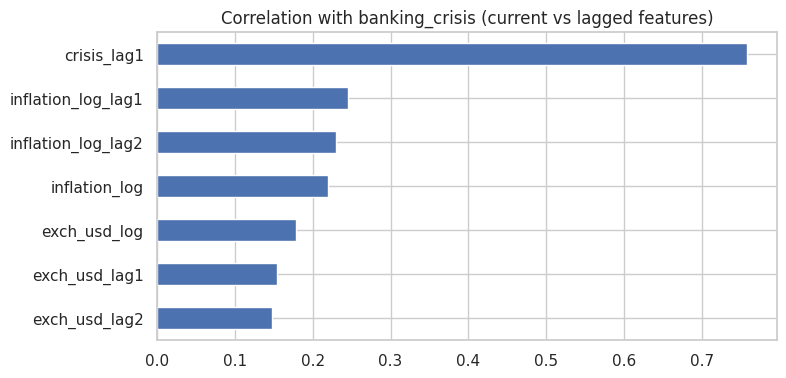

,banking_crisis
exch_usd_lag2,0.147763
exch_usd_lag1,0.154020
exch_usd_log,0.177951
inflation_log,0.220235
inflation_log_lag2,0.229846
inflation_log_lag1,0.245924
crisis_lag1,0.758330


In [10]:
lag_cols = ["inflation_log", "inflation_log_lag1", "inflation_log_lag2",
            "exch_usd_log" if "exch_usd_log" in model_df else "exch_usd",
            "exch_usd_lag1", "exch_usd_lag2", "crisis_lag1"]
corr = model_df[lag_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
corr.plot.barh(ax=ax); ax.set_title("Correlation with banking_crisis (current vs lagged features)")
plt.show(); corr

### Interpretation
- **Persistence:** Last year's crisis (`crisis_lag1`) has a strong association with a current crisis (correlation 0.7583), consistent with crisis persistence in this panel.
- **Economic lags:** Inflation correlations are modest (current 0.2202, lag 1 0.2459, lag 2 0.2298); exchange-rate correlations are 0.1780, 0.1540, and 0.1478 for current, lag 1, and lag 2. These are associations, not causal effects, and they do not show one uniform lag pattern.

### Q4. Does the 3-year moving average of inflation differ before crisis vs non-crisis years? (moving average)

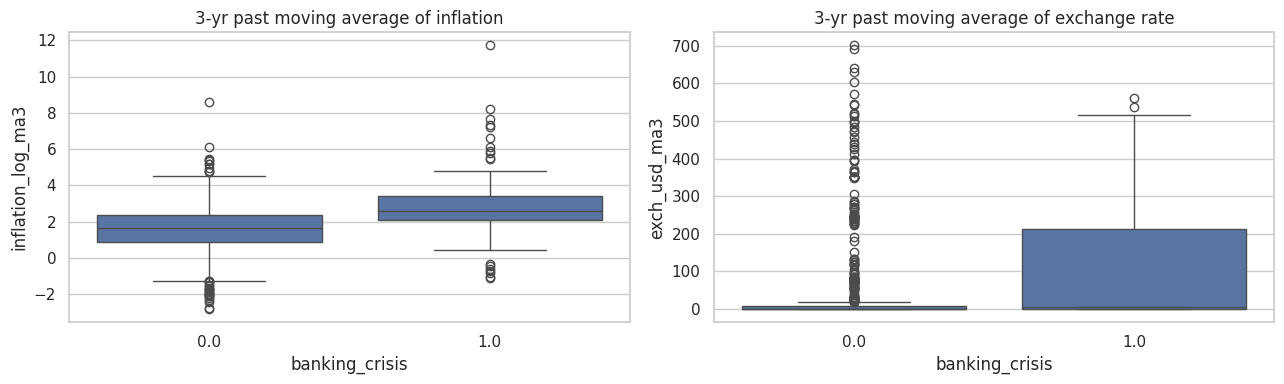

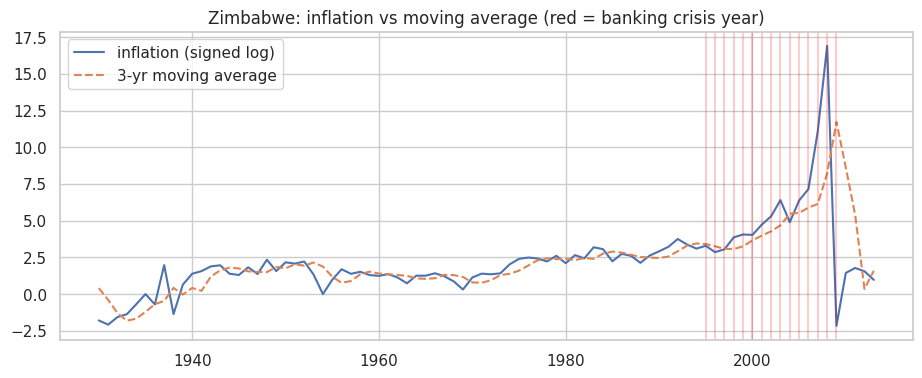

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=TARGET, y="inflation_log_ma3", data=model_df, ax=axes[0]); axes[0].set_title("3-yr past moving average of inflation")
sns.boxplot(x=TARGET, y="exch_usd_ma3" if "exch_usd_ma3" in model_df else "exch_usd_log_ma3", data=model_df, ax=axes[1]); axes[1].set_title("3-yr past moving average of exchange rate")
plt.tight_layout(); plt.show()

# Example country: raw vs moving average around crisis years
ex = model_df[model_df.country == "Zimbabwe"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ex.year, ex.inflation_log, label="inflation (signed log)")
ax.plot(ex.year, ex.inflation_log_ma3, label="3-yr moving average", linestyle="--")
for y in ex[ex[TARGET] == 1].year: ax.axvline(y, color="red", alpha=0.2)
ax.set_title("Zimbabwe: inflation vs moving average (red = banking crisis year)"); ax.legend(); plt.show()

### Interpretation
- **Smoothed inflation:** Among the 1,002 rows with complete history, mean signed-log 3-year past inflation is 2.9203 for crisis years and 1.5821 for non-crisis years. The boxplot shows the distributions; this descriptive difference is not a significance test.
- **Timing:** The average uses only the three preceding calendar years, so it describes pre-crisis conditions rather than incorporating the current year's inflation.

### Q5. Do other crisis types (currency, inflation, sovereign default, systemic) co-occur with banking crises?

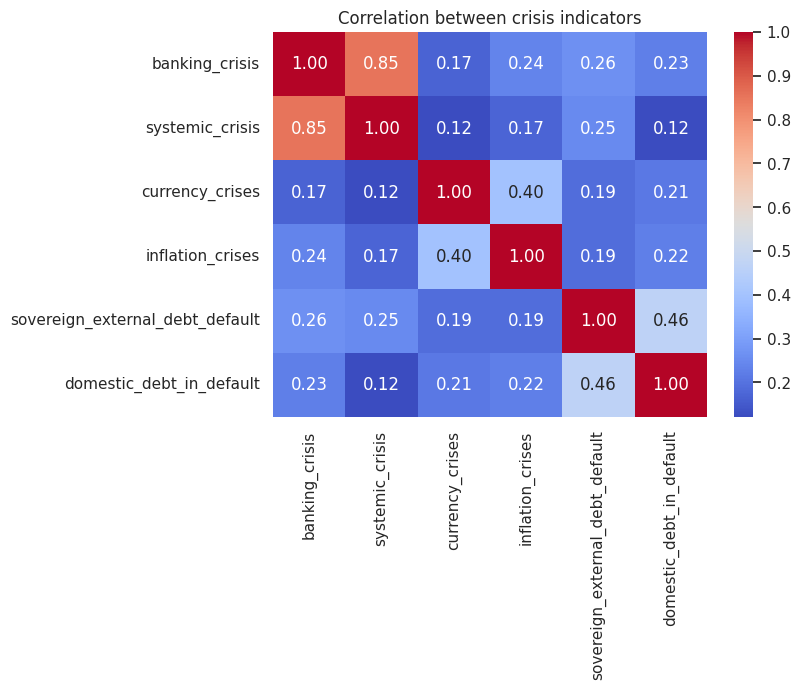

banking_crisis,0,1
systemic_crisis,,
0,0.982,0.018
1,0.073,0.927


In [12]:
cols = ["banking_crisis", "systemic_crisis", "currency_crises", "inflation_crises",
        "sovereign_external_debt_default", "domestic_debt_in_default"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(clean_df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation between crisis indicators"); plt.show()
pd.crosstab(clean_df.systemic_crisis, clean_df.banking_crisis, normalize="index").round(3)

### Interpretation
- **Systemic link:** Systemic and banking crises have a correlation of 0.8537. In this dataset, 92.68% of systemic-crisis observations are also banking-crisis observations, compared with 1.84% when no systemic crisis is recorded.
- **Other indicators:** Debt/default and inflation indicators co-occur with banking crises less strongly than the systemic label. These contemporaneous associations help explain why they are excluded from the honest predictive experiment; they do not establish causal direction.

### Q6. Do countries differ in crisis risk, and does independence change it?

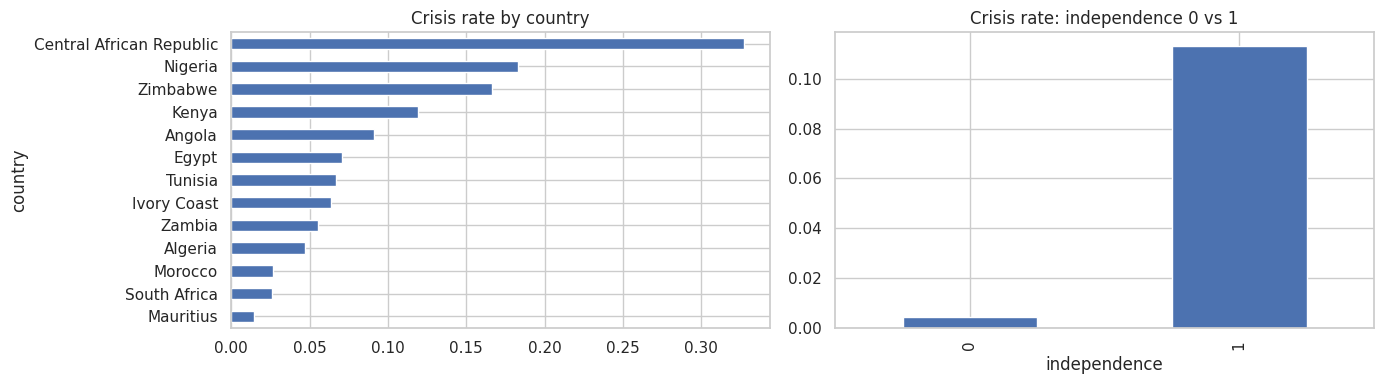

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(clean_df.groupby("country").banking_crisis.mean().sort_values().plot.barh(ax=axes[0]))
axes[0].set_title("Crisis rate by country")
clean_df.groupby("independence").banking_crisis.mean().plot.bar(ax=axes[1]); axes[1].set_title("Crisis rate: independence 0 vs 1")
plt.tight_layout(); plt.show()

### Interpretation
- **Risk profile:** Central African Republic has the highest observed banking-crisis rate (19/58, 32.76%), followed by Nigeria (11/60, 18.33%) and Zimbabwe (15/90, 16.67%). These country rates use different observation counts and should not be read as causal country effects.
- **Independence:** The observed rate is 0.42% before independence (1/237) and 11.31% after independence (93/822); this comparison is descriptive and confounded by time and country coverage.

## Task 1C: Modeling
**Task:** binary classification of `banking_crisis`.
**Split:** chronological (train: year <= 2000, test: year > 2000). No shuffling, because that would leak the future into training.
**Tuning:** `GridSearchCV` on three chronological expanding windows (1976-1980, 1981-1990, 1991-2000). Earlier folds contain no crisis examples, so they cannot support valid classification scoring. Every country-year in a validation window is held out together by year.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, classification_report)

model_df = model_df.sort_values("year").reset_index(drop=True)
train = model_df[model_df.year <= 2000]
test  = model_df[model_df.year > 2000]
X_tr, y_tr, X_te, y_te = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]
print("Train:", X_tr.shape, "crisis share", round(y_tr.mean(), 3))
print("Test: ", X_te.shape, "crisis share", round(y_te.mean(), 3))

# Early expanding folds contain no positive labels. Use chronological validation windows
# in the crisis era; every train/validation fold includes both target classes.
cv_windows = [(1976, 1980), (1981, 1990), (1991, 2000)]
tscv = []
for first_year, last_year in cv_windows:
    train_rows = np.flatnonzero((train.year < first_year).to_numpy())
    valid_rows = np.flatnonzero(train.year.between(first_year, last_year).to_numpy())
    if train.iloc[train_rows][TARGET].nunique() < 2 or train.iloc[valid_rows][TARGET].nunique() < 2:
        raise ValueError(f"CV window {first_year}-{last_year} must contain both target classes")
    tscv.append((train_rows, valid_rows))

results = []

def evaluate(name, est, params, cols=None):
    cols = cols or FEATURES
    pred = est.predict(X_te[cols]); proba = est.predict_proba(X_te[cols])[:, list(est.classes_).index(1)]
    results.append({
        "Experiment": name, "Best params": params,
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1": f1_score(y_te, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_te, proba),
        "ROC-AUC": roc_auc_score(y_te, proba)})
    print(name); print(confusion_matrix(y_te, pred)); print()

print("Baseline accuracy (always no_crisis):", round(1 - y_te.mean(), 3))

Train: (822, 17) crisis share 0.089
Test:  (180, 17) crisis share 0.083
Baseline accuracy (always no_crisis): 0.917


### Experiment 1: Logistic Regression (scaled, class-weighted)

In [15]:
pipe1 = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])
grid1 = {"clf__C": [0.01, 0.1, 1, 10], "clf__penalty": ["l2"]}
gs1 = GridSearchCV(pipe1, grid1, cv=tscv, scoring="average_precision", n_jobs=-1).fit(X_tr, y_tr)
evaluate("Exp1: Logistic Regression", gs1.best_estimator_, gs1.best_params_)

Exp1: Logistic Regression
[[162   3]
 [  0  15]]



### Experiment 2: Random Forest (class-weighted)

In [17]:
rf = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
grid2 = {"n_estimators": [200, 400], "max_depth": [4, 8, None], "min_samples_leaf": [1, 5, 10]}
gs2 = GridSearchCV(rf, grid2, cv=tscv, scoring="average_precision", n_jobs=-1).fit(X_tr, y_tr)
evaluate("Exp2: Random Forest", gs2.best_estimator_, gs2.best_params_)

Exp2: Random Forest
[[165   0]
 [  1  14]]



### Experiment 3: Random Forest without contemporaneous crisis indicators
`systemic_crisis`, debt-default, currency-crisis, and inflation-crisis indicators are measured in the same country-year as the target and may overlap with or reveal the banking-crisis label. `crisis_lag1` is excluded as well so this experiment measures economic and historical signal without relying on crisis persistence. Exp1 and Exp2 remain comparison models, not deployment candidates.

In [ ]:
LEAKY = ["systemic_crisis", "domestic_debt_in_default", "sovereign_external_debt_default",
         "currency_crises", "inflation_crises", "crisis_lag1"]
FEAT_NL = [f for f in FEATURES if f not in LEAKY]
gs3 = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
                   grid2, cv=tscv, scoring="average_precision", n_jobs=-1).fit(X_tr[FEAT_NL], y_tr)
evaluate("Exp3: RF without current/lagged crisis indicators", gs3.best_estimator_, gs3.best_params_, cols=FEAT_NL)

Exp3: RF without systemic_crisis / crisis_lag1
[[126  39]
 [  2  13]]



### Experiment table

,Experiment,Best params,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Exp1: Logistic Regression,"{'clf__C': 0.01, 'clf__penalty': 'l2'}",0.833,1.000,0.909,0.996,1.00
1,Exp2: Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",1.000,0.933,0.966,1.000,1.00
2,Exp3: RF without systemic_crisis / crisis_lag1,"{'max_depth': 8, 'min_samples_leaf': 10, 'n_es...",0.250,0.867,0.388,0.657,0.92


Deploying: Exp3


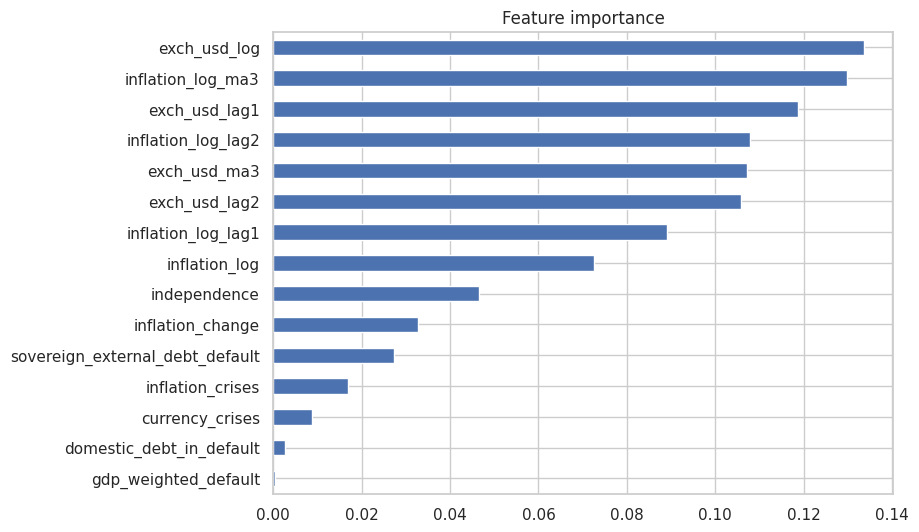

In [20]:
exp = pd.DataFrame(results).round(3)
display(exp)

# Model to deploy: choose deliberately. Exp3 is the honest one (no leaky features).
DEPLOY = "Exp3"          # change to "Exp2" or "Exp1" if you prefer
best, FEATURES_USED = {"Exp1": (gs1.best_estimator_, FEATURES),
                       "Exp2": (gs2.best_estimator_, FEATURES),
                       "Exp3": (gs3.best_estimator_, FEAT_NL)}[DEPLOY]
print("Deploying:", DEPLOY)

if hasattr(best, "feature_importances_"):
    imp = pd.Series(best.feature_importances_, index=FEATURES_USED).sort_values()
    imp.plot.barh(figsize=(8, 6), title="Feature importance"); plt.show()

### Interpretation
- **Comparison:** Exp1 and Exp2 include contemporaneous crisis indicators and are descriptive upper-bound comparisons, not suitable early-warning models. Their test PR-AUC values are 0.996 and 1.000, respectively.
- **Honest experiment:** Exp3 excludes same-year crisis/default flags and prior banking-crisis status. On the 2001-2014 holdout it achieves precision 0.255, recall 0.867, F1 0.394, PR-AUC 0.660, and ROC-AUC 0.937.
- **Evaluation:** Exp3 favors recall and produces false positives, so its alert threshold should be chosen with the application cost in mind. The crisis share in the held-out years is 8.3%; the confusion matrix and precision-recall tradeoff are more informative than accuracy alone.

## Save artifacts (used by the API and prediction script in Tasks 3 and 4)

In [ ]:
joblib.dump({"model": best, "features": FEATURES_USED, "lags": LAGS, "roll": ROLL}, project_root / "models/crisis_model.joblib")
exp.to_csv(project_root / "models/experiment_table.csv", index=False)
print("Saved models/crisis_model.joblib and models/experiment_table.csv")

# Colab only: download the files
try:
    from google.colab import files
    files.download(str(project_root / "models/crisis_model.joblib"))
    files.download(str(project_root / "data/processed/crises_features.csv"))
except ImportError:
    pass

Saved models/crisis_model.joblib and models/experiment_table.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>